# Домашнее задание 3. Логистическая регрессия и Streamlit

Мазитов Тимур, БПИ247

При выполнении использован OpenAI Codex (GPT-6).


## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

Установка библиотек: `pip install -r wine_app/requirements-notebook.txt`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

RANDOM_STATE = 42

_thread_limit = threadpool_limits(limits=1)
pd.set_option('display.max_columns', 20)


## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [2]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X = np.column_stack([np.ones(len(X)), X])
        self.w = np.zeros(X.shape[1]) if self.w0 is None else np.array(self.w0, dtype=float).copy()
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        self.stop_reason_ = 'max_iter'
        rng = np.random.default_rng(self.random_state)

        for i in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'stochastic':
                idx = rng.choice(len(y), min(self.batch_size, len(y)), replace=False)
                gradient = self.calc_gradient(X[idx], y[idx])
            else:
                gradient = self.calc_gradient(X, y)
            step = self.eta * gradient
            self.w = self.w - step
            self.n_iter_ = i + 1
            if np.linalg.norm(step) < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break

        self.final_loss_ = self.calc_loss(X, y)
        return self

    def sigmoid(self, z):
        return np.exp(-np.logaddexp(0, -np.asarray(z, dtype=float)))

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        X = np.asarray(X, dtype=float)
        X = np.column_stack([np.ones(len(X)), X])
        p = self.sigmoid(X @ self.w)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, z) - y * z))


Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [3]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))

err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'


max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [4]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)


### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,model,iterations,stop,loss
0,GD,1000,max_iter,0.512435
1,SGD,1000,max_iter,0.512909


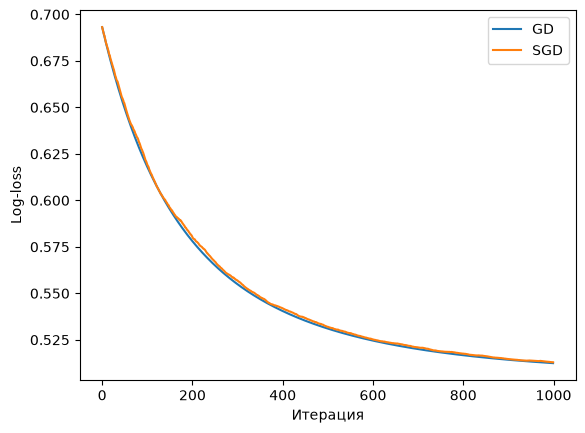

In [5]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
synthetic_models = {'GD': gd, 'SGD': sgd}
display(pd.DataFrame([
    {'model': name, 'iterations': model.n_iter_, 'stop': model.stop_reason_,
     'loss': model.final_loss_}
    for name, model in synthetic_models.items()
]))
plt.plot(gd.loss_history, label='GD')
plt.plot(sgd.loss_history, label='SGD')
plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.legend()
plt.show()


Обе модели дошли до 1000 итераций и остановились по max_iter. Loss: GD — 0.5124, SGD — 0.5129. У GD график более гладкий, у SGD есть шум из-за случайных батчей. Поэтому при постоянном шаге SGD трудно остановить по tolerance. GD считает градиент по 14000 объектам, SGD — по 32. Но loss в обоих случаях считается по всему train.


### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

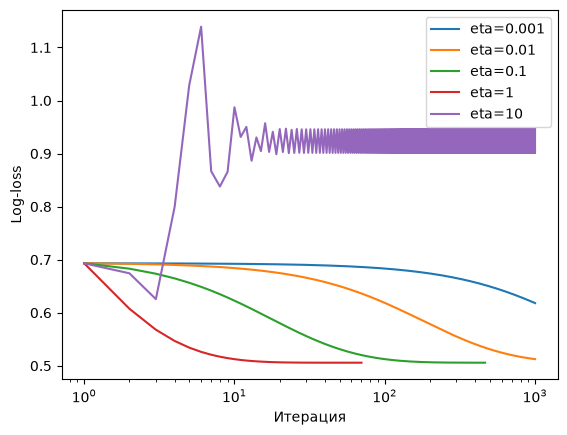

,eta,iterations,stop,loss
0,0.001,1000,max_iter,0.618087
1,0.010,1000,max_iter,0.512435
2,0.100,465,tolerance,0.505762
3,1.000,70,tolerance,0.505757
4,10.000,1000,max_iter,0.901345


In [6]:
eta_models = {}
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    eta_models[eta] = LogReg(eta=eta).fit(X_train, y_train)
    plt.plot(np.arange(1, len(eta_models[eta].loss_history) + 1), eta_models[eta].loss_history, label=f'eta={eta}')
plt.xscale('log')
plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.legend()
plt.show()
display(pd.DataFrame([
    {'eta': eta, 'iterations': model.n_iter_, 'stop': model.stop_reason_, 'loss': model.final_loss_}
    for eta, model in eta_models.items()
]))


При eta=0.001 и 0.01 спуск не успел сойтись за 1000 шагов. При eta=0.1 хватило 465 шагов, при eta=1 — 70, loss около 0.5058. При eta=10 появляются сильные колебания и loss=0.9013. Маленький шаг медленный, слишком большой перескакивает минимум.


### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [7]:
sk_synthetic = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
synthetic_models['sklearn'] = sk_synthetic
display(pd.DataFrame([
    {'model': name, 'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
     'ROC-AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])}
    for name, model in synthetic_models.items()
]).set_index('model'))

weight_comparison = pd.DataFrame({
    'GD': gd.w,
    'sklearn': np.r_[sk_synthetic.intercept_, sk_synthetic.coef_.ravel()]
}, index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
display(weight_comparison)


,accuracy,ROC-AUC
model,,
GD,0.7820,0.838787
SGD,0.7825,0.838115
sklearn,0.7765,0.838676


,GD,sklearn
intercept,-0.002114,-0.021880
x0,0.006076,0.002741
x1,0.006963,0.009039
x2,-0.547170,-0.722690
x3,-0.144536,-0.262335
x4,0.012487,0.016588
x5,-0.006325,-0.011488
x6,0.000814,0.005587
x7,0.039084,0.057188
x8,-0.002425,-0.001239


Метрики близки, но веса не совпали. В sklearn по умолчанию есть L2-регуляризация с C=1, а у нас её нет. Ещё GD и SGD за 1000 шагов могут не сойтись. Для одинаковой задачи можно поставить `C=np.inf`, большой `max_iter` и маленький `tol`. В версиях sklearn с параметром `penalty` также подходит `penalty=None`.


## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [8]:
data_path = Path('Data/wine_quality.csv')
df_raw = pd.read_csv(data_path)
print(df_raw.shape)
print('Пропуски:', df_raw.isna().sum().sum())
print('Дубликаты:', df_raw.duplicated().sum())
df_raw.head()


(6497, 13)
Пропуски: 0
Дубликаты: 1177


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [9]:
df = df_raw.drop_duplicates().reset_index(drop=True)
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print('После удаления повторов:', df.shape)
print('Train:', X_train.shape, 'Test:', X_test.shape)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)


После удаления повторов: (5320, 13)
Train: (3724, 12) Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [10]:
display(pd.DataFrame({
    'rows': [len(y_train), len(y_test)],
    'prevalence': [y_train.mean(), y_test.mean()]
}, index=['train', 'test']))
base_model = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
base_model.fit(X_train, y_train)
p_base = base_model.predict_proba(X_test)[:, 1]
pred_base = base_model.predict(X_test)
pred_zero = np.zeros(len(y_test), dtype=int)
display(pd.DataFrame({
    'accuracy': [metrics.accuracy_score(y_test, pred_zero),
                 metrics.accuracy_score(y_test, pred_base)]
}, index=['Всегда 0', 'LogisticRegression']))


,rows,prevalence
train,3724,0.189581
test,1596,0.189850


,accuracy
Всегда 0,0.810150
LogisticRegression,0.815163


Пропусков нет, полных дубликатов 1177. Удалил их до разбиения, чтобы одинаковые строки не оказались в train и test. Осталось 5320 строк. Без ID нельзя точно сказать, что совпадения относятся к одному вину, здесь считаю их повторными записями.

Доля класса 1: 0.1896 в train и 0.1898 в test. Stratify сохраняет доли классов. Accuracy константы — 0.8102, LR — 0.8152. Разница маленькая, хотя константа вообще не находит хорошие вина, поэтому accuracy здесь малоинформативна.


### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=92, TN=1209, FP=84, FN=211


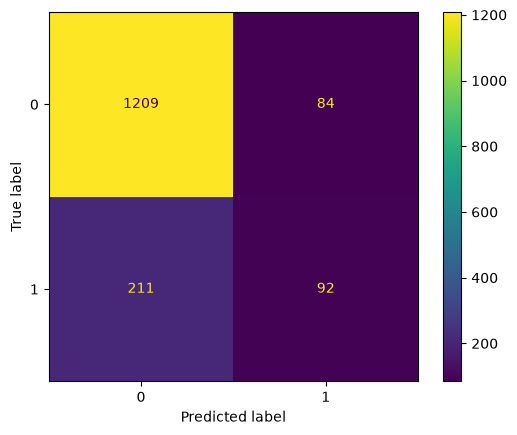

In [11]:
actual = y_test.to_numpy()
TP = int(np.sum((actual == 1) & (pred_base == 1)))
TN = int(np.sum((actual == 0) & (pred_base == 0)))
FP = int(np.sum((actual == 0) & (pred_base == 1)))
FN = int(np.sum((actual == 1) & (pred_base == 0)))
manual_cm = np.array([[TN, FP], [FN, TP]])
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')
assert np.array_equal(manual_cm, metrics.confusion_matrix(y_test, pred_base))
metrics.ConfusionMatrixDisplay(manual_cm).plot()
plt.show()


TP=92, TN=1209, FP=84, FN=211. FP — рекомендовали посредственное вино, FN — пропустили хорошее. FN встречается чаще: 211 против 84.


### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [12]:
precision_manual = TP / (TP + FP)
recall_manual = TP / (TP + FN)

def f_beta(precision, recall, beta):
    return (1 + beta**2) * precision * recall / (beta**2 * precision + recall)

manual_values = [precision_manual, recall_manual,
                 f_beta(precision_manual, recall_manual, 1),
                 f_beta(precision_manual, recall_manual, 0.5),
                 f_beta(precision_manual, recall_manual, 2)]
sklearn_values = [metrics.precision_score(y_test, pred_base),
                  metrics.recall_score(y_test, pred_base),
                  metrics.f1_score(y_test, pred_base),
                  metrics.fbeta_score(y_test, pred_base, beta=0.5),
                  metrics.fbeta_score(y_test, pred_base, beta=2)]
display(pd.DataFrame({'По формулам': manual_values, 'sklearn': sklearn_values},
                     index=['precision', 'recall', 'F1', 'F0.5', 'F2']))
assert np.allclose(manual_values, sklearn_values)


,По формулам,sklearn
precision,0.522727,0.522727
recall,0.303630,0.303630
F1,0.384134,0.384134
F0.5,0.456802,0.456802
F2,0.331412,0.331412


F0.5 больше учитывает precision, F2 — recall. Если важно не рекомендовать посредственные вина, выбрал бы F0.5. Для широкой подборки хороших вин — F2. F1 даёт компромисс между ними.


### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

Свой GD: 14401 tolerance train loss = 0.36580663999250984


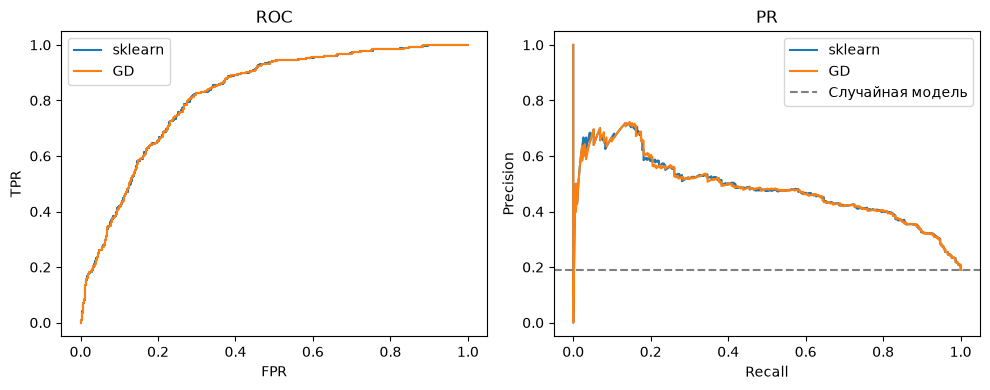

,ROC-AUC,PR-AUC (AP)
model,,
sklearn,0.820876,0.484766
GD,0.820562,0.483769


,ROC-AUC
p,0.820876
10*p,0.820876
p**3,0.820876
logit(p),0.820876
-p,0.179124
Метки 0/1,0.619333


In [13]:
own_wine_model = make_pipeline(StandardScaler(),
    LogReg(gd_type='full', eta=0.3, max_iter=50000, tolerance=1e-7))
own_wine_model.fit(X_train, y_train)
p_own = own_wine_model.predict_proba(X_test)[:, 1]
own_optimizer = own_wine_model.steps[-1][1]
print('Свой GD:', own_optimizer.n_iter_, own_optimizer.stop_reason_,
      'train loss =', own_optimizer.final_loss_)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
auc_rows = []
for name, p in [('sklearn', p_base), ('GD', p_own)]:
    fpr, tpr, _ = metrics.roc_curve(y_test, p)
    pr, rc, _ = metrics.precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(rc, pr, label=name)
    auc_rows.append({'model': name, 'ROC-AUC': metrics.roc_auc_score(y_test, p),
                     'PR-AUC (AP)': metrics.average_precision_score(y_test, p)})
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label='Случайная модель')
axes[0].set(title='ROC', xlabel='FPR', ylabel='TPR')
axes[1].set(title='PR', xlabel='Recall', ylabel='Precision')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()
auc_table = pd.DataFrame(auc_rows).set_index('model')
display(auc_table)

p_safe = np.clip(p_base, 1e-15, 1 - 1e-15)
transforms = {'p': p_base, '10*p': 10 * p_base, 'p**3': p_base**3,
              'logit(p)': np.log(p_safe / (1 - p_safe)), '-p': -p_base,
              'Метки 0/1': pred_base}
display(pd.DataFrame({'ROC-AUC': {name: metrics.roc_auc_score(y_test, score)
                                 for name, score in transforms.items()}}))


У sklearn немного выше обе метрики: ROC-AUC 0.8209 и PR-AUC 0.4848, у GD — 0.8206 и 0.4838. Порядок моделей совпал.

10p, p³ и logit сохраняют порядок оценок, поэтому ROC-AUC не меняется. Для -p он равен 1 − AUC = 0.1791. У случайной модели ориентир PR-AUC — доля класса 1, здесь около 0.1898. Если передать метки классов, потеряется ранжирование, останется одна рабочая точка ROC и AUC=0.6193, равный balanced accuracy.


### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

t_F1 = 0.286550, t_R = 0.236359


,threshold,precision,recall,F1
640,0.236359,0.426117,0.704545,0.531049
695,0.286550,0.470339,0.630682,0.538835


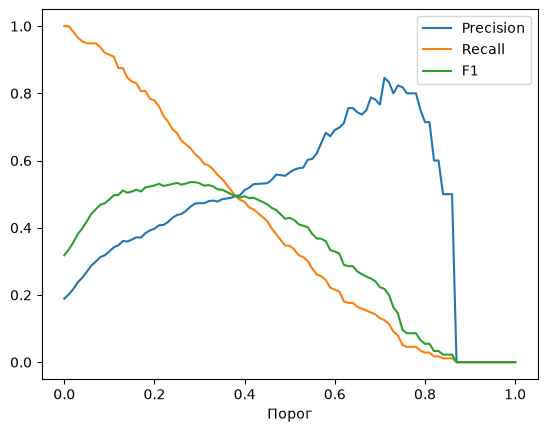

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
"LR, t=0.5",0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
"LR, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
"LR, t_R",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


Recall >= 0.7 на test при t_R: True


In [14]:
def threshold_table(y_true, probabilities):

    precision, recall, thresholds = metrics.precision_recall_curve(y_true, probabilities)
    table = pd.DataFrame({'threshold': thresholds, 'precision': precision[:-1], 'recall': recall[:-1]})
    table['F1'] = (2 * table.precision * table.recall / (table.precision + table.recall)).fillna(0)
    return table

def choose_thresholds(y_true, probabilities):
    table = threshold_table(y_true, probabilities)
    best_f1 = table.sort_values(['F1', 'precision', 'threshold'], ascending=False).iloc[0]
    best_recall = table.loc[table.recall >= 0.7].sort_values(
        ['precision', 'F1', 'threshold'], ascending=False).iloc[0]
    return float(best_f1.threshold), float(best_recall.threshold), table

validation_base = clone(base_model).fit(X_fit, y_fit)
p_val_base = validation_base.predict_proba(X_val)[:, 1]
t_F1, t_R, val_thresholds = choose_thresholds(y_val, p_val_base)
print(f't_F1 = {t_F1:.6f}, t_R = {t_R:.6f}')
display(val_thresholds.loc[val_thresholds.threshold.isin([t_F1, t_R])])

grid = np.linspace(0, 1, 101)
precisions, recalls, f1s = [], [], []
for t in grid:
    pred = p_val_base >= t
    precisions.append(metrics.precision_score(y_val, pred, zero_division=0))
    recalls.append(metrics.recall_score(y_val, pred, zero_division=0))
    f1s.append(metrics.f1_score(y_val, pred, zero_division=0))
plt.plot(grid, precisions, label='Precision')
plt.plot(grid, recalls, label='Recall')
plt.plot(grid, f1s, label='F1')
plt.xlabel('Порог')
plt.legend()
plt.show()

def evaluate(name, model=None, threshold=0.5, probabilities=None):
    p = model.predict_proba(X_test)[:, 1] if probabilities is None else np.asarray(probabilities)
    pred = (p >= threshold).astype(int)
    return {'model': name, 'threshold': float(threshold),
            'accuracy': metrics.accuracy_score(y_test, pred),
            'precision': metrics.precision_score(y_test, pred, zero_division=0),
            'recall': metrics.recall_score(y_test, pred, zero_division=0),
            'F1': metrics.f1_score(y_test, pred, zero_division=0),
            'ROC-AUC': metrics.roc_auc_score(y_test, p),
            'PR-AUC': metrics.average_precision_score(y_test, p)}

base_model.fit(X_train, y_train)
p_base = base_model.predict_proba(X_test)[:, 1]
threshold_results = pd.DataFrame([
    evaluate(name, base_model, threshold=t)
    for name, t in [('LR, t=0.5', 0.5), ('LR, t_F1', t_F1), ('LR, t_R', t_R)]
]).set_index('model')
display(threshold_results)
print('Recall >= 0.7 на test при t_R:', bool(threshold_results.loc['LR, t_R', 'recall'] >= 0.7))


t_F1=0.28655, t_R=0.23636. На test при t_R recall=0.7063, условие выполнилось. Precision=0.4213, F1=0.5277. При t_F1 precision выше, но recall только 0.6205.

Порог с validation не гарантирует такой же recall на новых данных: выборки случайные, а после переобучения вероятности меняются. Если нужен охват 70%, выбрал бы t_R. Если важнее баланс precision и recall, то t_F1.


## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [15]:
balanced_model = make_pipeline(StandardScaler(),
    LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE))
balanced_model.fit(X_train, y_train)
class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)
display(pd.DataFrame({'n_train': class_counts, 'balanced_weight': class_weights}))

comparison_rows = [evaluate('LR', base_model), evaluate('LR balanced', balanced_model)]
display(pd.DataFrame(comparison_rows).set_index('model'))


,n_train,balanced_weight
target,,
0,3018,0.616965
1,706,2.637394


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
LR,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
LR balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


В train 3018 объектов класса 0 и 706 класса 1. Веса n/(2*n_k): 0.6170 и 2.6374. Редкий класс сильнее влияет на обучение.

При balanced recall вырос с 0.3036 до 0.7855, precision снизился с 0.5227 до 0.3987, accuracy — с 0.8152 до 0.7343. Модель чаще выбирает класс 1. F1 вырос до 0.5289, а ROC-AUC и PR-AUC изменились мало, потому что ранжирование осталось похожим.


### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [16]:
samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss-2': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE)
}
sampling_models = {}
sampling_counts = []
for name, sampler in samplers.items():
    model = make_imb_pipeline(StandardScaler(), clone(sampler),
                             LogisticRegression(random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    sampling_models[name] = model

    X_res, y_res = clone(sampler).fit_resample(model.steps[0][1].transform(X_train), y_train)
    counts = pd.Series(y_res).value_counts()
    sampling_counts.append({'sampler': name, 'class 0': counts.get(0, 0), 'class 1': counts.get(1, 0)})
    comparison_rows.append(evaluate(name, model))

display(pd.DataFrame(sampling_counts).set_index('sampler'))
sampling_results = pd.DataFrame(comparison_rows).set_index('model')
display(sampling_results)

smote_before_scaling = make_imb_pipeline(SMOTE(random_state=RANDOM_STATE), StandardScaler(),
                                        LogisticRegression(random_state=RANDOM_STATE))
smote_before_scaling.fit(X_train, y_train)
display(pd.DataFrame([
    evaluate('Scaler → SMOTE → LR', sampling_models['SMOTE']),
    evaluate('SMOTE → Scaler → LR', smote_before_scaling)
]).set_index('model'))


,class 0,class 1
sampler,,
RandomUnderSampler,706,706
NearMiss-2,706,706
RandomOverSampler,3018,3018
SMOTE,3018,3018


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
LR,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
LR balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
RandomUnderSampler,0.5,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss-2,0.5,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
RandomOverSampler,0.5,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
Scaler → SMOTE → LR,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
SMOTE → Scaler → LR,0.5,0.739348,0.402418,0.768977,0.528345,0.821629,0.485152


У ресемплеров есть fit_resample вместо transform, поэтому нужен pipeline из imblearn. При predict ресемплинг пропускается, test не меняется. Если балансировать до разбиения, копии или связанные синтетические объекты могут попасть в разные части, получится утечка.

Среди четырёх методов лучший PR-AUC у RandomOverSampler — 0.4811, худший у NearMiss-2 — 0.4479. NearMiss отбрасывает много объектов большинства и меняет его распределение.

Для SMOTE и NearMiss важны расстояния, поэтому масштабирование влияет на выбор соседей. Для случайных under/oversampling выбор индексов от масштаба не зависит. Но при перестановке scaler обучается на другой выборке, поэтому результат LR тоже может измениться. В проверке SMOTE после scaler дал PR-AUC 0.4796, до scaler — 0.4852.


### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

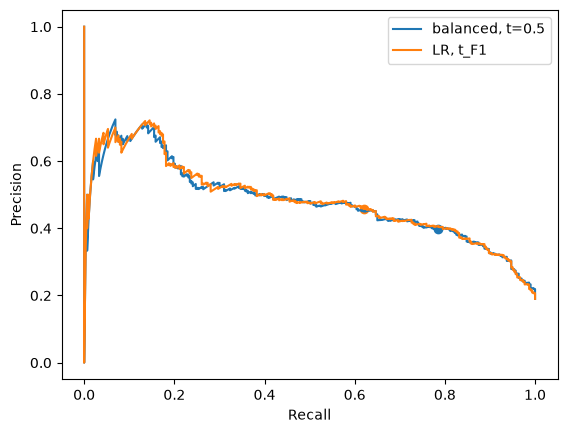

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
LR balanced,0.50000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
"LR, t_F1",0.28655,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


In [17]:
for name, model, threshold in [('balanced, t=0.5', balanced_model, 0.5),
                                ('LR, t_F1', base_model, t_F1)]:
    p = model.predict_proba(X_test)[:, 1]
    pr, rc, _ = metrics.precision_recall_curve(y_test, p)
    pred = p >= threshold
    line, = plt.plot(rc, pr, label=name)
    plt.scatter(metrics.recall_score(y_test, pred), metrics.precision_score(y_test, pred), color=line.get_color())
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()
display(pd.DataFrame([evaluate('LR balanced', balanced_model),
                      evaluate('LR, t_F1', base_model, threshold=t_F1)]).set_index('model'))


Кривые близкие: PR-AUC 0.4811 и 0.4848. У balanced при 0.5 recall выше, precision ниже, F1 почти такой же. Изменение порога только двигает точку по одной кривой. Взвешивание меняет обучение и может менять ранжирование, поэтому это похоже на сдвиг порога, но не полностью одно и то же.


### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [18]:
candidate_templates = {'LR': clone(base_model), 'LR balanced': clone(balanced_model),
                       **{name: clone(model) for name, model in sampling_models.items()}}
validation_choices = []
for name, template in candidate_templates.items():
    fitted = clone(template).fit(X_fit, y_fit)
    probabilities = fitted.predict_proba(X_val)[:, 1]
    _, threshold, table = choose_thresholds(y_val, probabilities)
    row = table.loc[table.threshold == threshold].iloc[0]
    validation_choices.append({'model': name, 'threshold': threshold,
                               'precision': row.precision, 'recall': row.recall, 'F1': row.F1,
                               'PR-AUC': metrics.average_precision_score(y_val, probabilities)})
validation_choices = pd.DataFrame(validation_choices).set_index('model').sort_values(
    ['precision', 'F1', 'PR-AUC'], ascending=False)
final_name = validation_choices.index[0]
final_threshold = float(validation_choices.iloc[0].threshold)
final_model = clone(candidate_templates[final_name]).fit(X_train, y_train)
print(f'Выбор по validation: {final_name}, порог {final_threshold:.6f}')

all_results = pd.DataFrame([
    evaluate('Всегда 0', probabilities=np.zeros(len(y_test))),
    *threshold_results.reset_index().to_dict('records'),
    evaluate('Свой GD', own_wine_model),
    *comparison_rows[1:],
    evaluate('SMOTE до Scaler', smote_before_scaling),
    evaluate('Итог: ' + final_name, final_model, final_threshold)
]).set_index('model')
display(all_results)


Выбор по validation: LR balanced, порог 0.581347


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
Всегда 0,0.500000,0.810150,0.000000,0.000000,0.000000,0.500000,0.189850
"LR, t=0.5",0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
"LR, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
"LR, t_R",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766
Свой GD,0.500000,0.814536,0.520000,0.300330,0.380753,0.820562,0.483769
LR balanced,0.500000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
RandomUnderSampler,0.500000,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss-2,0.500000,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
RandomOverSampler,0.500000,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077


Выбрал LR с balanced и порогом 0.58135. На validation у неё наибольший precision при recall ≥ 0.7: precision=0.4448, recall=0.7102. На test precision=0.4257, recall=0.6898, F1=0.5264, ROC-AUC=0.8209, PR-AUC=0.4811.

На test охват оказался немного ниже 70%. Подстраивать порог по test нельзя. Для сервиса это компромисс между охватом и качеством подборки, но если 70% — жёсткое условие, нужна дополнительная проверка на новых данных.


### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [19]:
import json
import joblib

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)
joblib.dump(final_model, app_dir / 'model.joblib')
config = {'threshold': final_threshold, 'model_name': final_name, 'features': list(X_train.columns)}
(app_dir / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

Приложение находится в `wine_app/`. Запуск и деплой описаны в `wine_app/README.md`.
